# Legacy vs. conformal wakefield simulation

This notebook compares the existing **legacy** STL discretization with the new
**conformal** geometry pipeline for the standard WAKIS cavity geometry.

Both simulations use exactly the same:

- cavity and shell STL files,
- Cartesian grid,
- beam parameters,
- wake length,
- PEC outer boundary conditions.

The material setup is:

- `cavity` → vacuum,
- `shell` → PEC,
- background → PEC.

The purpose is to compare the resulting wake potential and longitudinal impedance.
No analytical resonance frequencies are used because the cavity has smooth
pipe-to-cavity transitions and is not an ideal pillbox.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from tqdm.auto import tqdm

from wakis import GridFIT3D, SolverFIT3D, WakeSolver

## Geometry and common simulation parameters

The notebook is assumed to live in the `notebooks` directory, so the existing
test STL files are addressed directly with relative paths.


In [12]:
cavity_path = Path("../tests/stl/007_vacuum_cavity.stl")
shell_path = Path("../tests/stl/007_lossymetal_shell.stl")

stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
}

# stl_materials = {
#     "cavity": "vacuum",
#     "shell": [10.0, 1.0,10.0],
# }

# stl_material_types = {
#     "cavity": "normal",
#     "shell": "normal",
# }

solids = pv.read(cavity_path) + pv.read(shell_path)
xmin, xmax, ymin, ymax, zmin, zmax = solids.bounds

# Same Cartesian mesh for both simulations.
Nx = 20
Ny = 20
Nz = 60

# Beam parameters.
sigmaz = 10e-2
q = 1e-9
beta = 1.0

xsource = 0.0
ysource = 0.0
xtest = 0.0
ytest = 0.0

# Wake calculation.
wakelength = 100.0
skip_cells = 5

wake_cfln = 0.4
conformal_eta = 0.2

# Closed PEC computational domain.
bc_low = ["pec", "pec", "pec"]
bc_high = ["pec", "pec", "pec"]

dtype = np.float32

results_root = Path("_conformal_pillbox_wake")
results_root.mkdir(exist_ok=True)

## Time-domain stability test with a local electric-field excitation

Before running the wakefield simulations, the time-domain stability of the
different geometry treatments is compared directly.

A single local $E_z$ degree of freedom near the center of the cavity is
initialized to unit amplitude. No source is applied afterwards: the fields
are advanced only with the solver's normal `one_step()` routine. The maximum
absolute electric and magnetic field amplitudes are recorded at every time
step.

Four cases are compared with the same Cartesian mesh, material definitions,
boundary conditions, CFL number, and initial excitation:

- **Legacy**
- **Conformal, $\eta=0$**: conformal PEC snapping disabled
- **Conformal, $\eta=0.2$**
- **Conformal, $\eta=0.4$**: deliberately aggressive snapping for comparison

Here $\eta=`conformal_pec_snap_fraction`. The test is intended as a
numerical stability diagnostic rather than as a quantitative excitation model.
In particular, the Cartesian CFL time step is left unchanged so that the effect
of removing very small conformal metric fractions can be seen directly.


In [6]:
td_cases = [
    {
        "label": "Legacy",
        "geometry_mode": "legacy",
        "snap_fraction": None,
    },
    {
        "label": r"Conformal, $\eta=0$",
        "geometry_mode": "conformal",
        "snap_fraction": 0.0,
    },
    {
        "label": r"Conformal, $\eta=0.2$",
        "geometry_mode": "conformal",
        "snap_fraction": 0.2,
    },
    {
        "label": r"Conformal, $\eta=0.25$",
        "geometry_mode": "conformal",
        "snap_fraction": 0.25,
    },
    {
        "label": r"Conformal, $\eta=0.3$",
        "geometry_mode": "conformal",
        "snap_fraction": 0.3,
    },
    {
        "label": r"Conformal, $\eta=0.35$",
        "geometry_mode": "conformal",
        "snap_fraction": 0.35,
    },
    {
        "label": r"Conformal, $\eta=0.4$",
        "geometry_mode": "conformal",
        "snap_fraction": 0.4,
    },
]

td_steps = 3000
td_cfln = 0.5
td_initial_ez = 1.0
td_blowup_limit = 1.0e12

td_results = {}

for case in td_cases:
    print()
    print("=" * 78)
    print(case["label"])
    print("=" * 78)

    grid_kwargs = dict(
        xmin=xmin,
        xmax=xmax,
        ymin=ymin,
        ymax=ymax,
        zmin=zmin,
        zmax=zmax,
        Nx=Nx,
        Ny=Ny,
        Nz=Nz,
        stl_solids=stl_solids,
        stl_materials=stl_materials,
        stl_material_types=stl_material_types,
        stl_method="voxelize_rectilinear",
        geometry_mode=case["geometry_mode"],
        subpixel_smoothing=False,
        stl_scale=1.0,
        stl_rotate=[0.0, 0.0, 0.0],
        stl_translate=[0.0, 0.0, 0.0],
        verbose=0,
    )

    if case["geometry_mode"] == "conformal":
        grid_kwargs["bg_material_type"] = "normal"
        grid_kwargs["conformal_pec_snap_fraction"] = case["snap_fraction"]

    td_grid = GridFIT3D(**grid_kwargs)

    td_solver = SolverFIT3D(
        td_grid,
        wake=None,
        cfln=td_cfln,
        bc_low=bc_low,
        bc_high=bc_high,
        use_stl=True,
        bg=[10.0, 1.0],
        dtype=dtype,
        use_gpu=False,
        verbose=0,
    )

    # Use the same physical source location in every case.
    source_ix = int(np.argmin(np.abs(td_solver.x - 0.0)))
    source_iy = int(np.argmin(np.abs(td_solver.y - 0.0)))
    source_iz = int(np.argmin(np.abs(td_solver.z - 0.5 * (zmin + zmax))))

    source_position = (
        float(td_solver.x[source_ix]),
        float(td_solver.y[source_iy]),
        float(td_solver.z[source_iz]),
    )

    # Local broadband initial excitation. No source is applied after t=0.
    td_solver.E[
        source_ix,
        source_iy,
        source_iz,
        "z",
    ] = td_initial_ez

    times = np.full(td_steps + 1, np.nan)
    max_e = np.full(td_steps + 1, np.nan)
    max_h = np.full(td_steps + 1, np.nan)

    times[0] = 0.0
    max_e[0] = np.max(np.abs(td_solver.E.toarray()))
    max_h[0] = np.max(np.abs(td_solver.H.toarray()))

    completed_steps = td_steps

    for n in tqdm(
        range(1, td_steps + 1),
        desc=case["label"],
        leave=False,
    ):
        td_solver.one_step()

        times[n] = n * td_solver.dt
        max_e[n] = np.max(np.abs(td_solver.E.toarray()))
        max_h[n] = np.max(np.abs(td_solver.H.toarray()))

        finite = np.isfinite(max_e[n]) and np.isfinite(max_h[n])

        if not finite or max_e[n] > td_blowup_limit or max_h[n] > td_blowup_limit:
            completed_steps = n
            print(
                "Stopped early at step "
                f"{n}: "
                f"max|E|={max_e[n]:.3e}, "
                f"max|H|={max_h[n]:.3e}"
            )
            break

    td_results[case["label"]] = {
        "time": times[: completed_steps + 1],
        "max_e": max_e[: completed_steps + 1],
        "max_h": max_h[: completed_steps + 1],
        "dt": float(td_solver.dt),
        "completed_steps": completed_steps,
        "source_position": source_position,
    }

    print(
        f"dt = {td_solver.dt:.6e} s, "
        f"source = "
        f"({source_position[0]:.4f}, "
        f"{source_position[1]:.4f}, "
        f"{source_position[2]:.4f}) m"
    )
    print(f"maximum recorded |E| = {np.nanmax(max_e[: completed_steps + 1]):.6e}")
    print(f"maximum recorded |H| = {np.nanmax(max_h[: completed_steps + 1]):.6e}")


Legacy
Generating grid with 24000 mesh cells...
Initializing Electromagnetic solver...


Legacy:   0%|          | 0/3000 [00:00<?, ?it/s]

dt = 1.800177e-11 s, source = (0.0130, 0.0130, 0.1433) m
maximum recorded |E| = 1.000000e+00
maximum recorded |H| = 8.027238e-04

Conformal, $\eta=0$
Generating grid with 24000 mesh cells...
Initializing Electromagnetic solver...


Conformal, $\eta=0$:   0%|          | 0/3000 [00:00<?, ?it/s]

Stopped early at step 25: max|E|=1.504e+15, max|H|=7.266e+08
dt = 1.800177e-11 s, source = (0.0130, 0.0130, 0.1433) m
maximum recorded |E| = 1.504014e+15
maximum recorded |H| = 7.266157e+08

Conformal, $\eta=0.2$
Generating grid with 24000 mesh cells...
Initializing Electromagnetic solver...


...

Initializing Electromagnetic solver...


Conformal, $\eta=0.35$:   0%|          | 0/3000 [00:00<?, ?it/s]

dt = 1.800177e-11 s, source = (0.0130, 0.0130, 0.1433) m
maximum recorded |E| = 1.000000e+00
maximum recorded |H| = 8.027238e-04

Conformal, $\eta=0.4$
Generating grid with 24000 mesh cells...
Initializing Electromagnetic solver...


Conformal, $\eta=0.4$:   0%|          | 0/3000 [00:00<?, ?it/s]

dt = 1.800177e-11 s, source = (0.0130, 0.0130, 0.1433) m
maximum recorded |E| = 1.000000e+00
maximum recorded |H| = 8.027238e-04


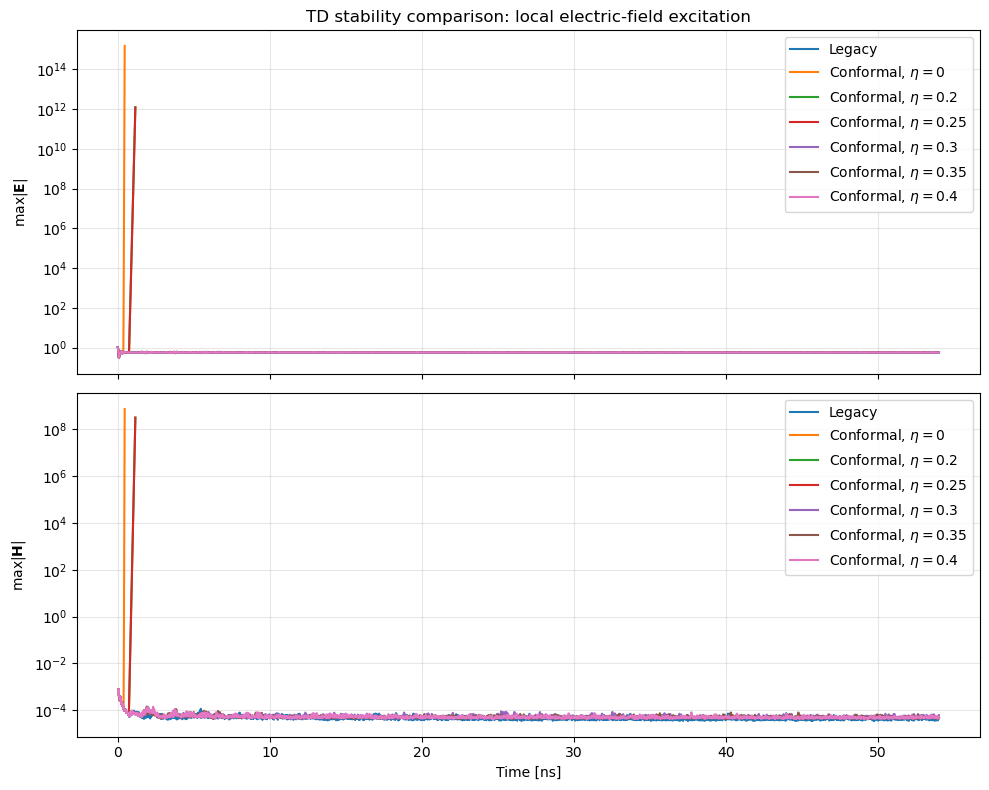


Summary
------------------------------------------------------------------------------
Legacy                       dt=1.800177e-11 s, steps=3000, max|E|=1.000000e+00, max|H|=8.027238e-04
Conformal, $\eta=0$          dt=1.800177e-11 s, steps=  25, max|E|=1.504014e+15, max|H|=7.266157e+08
Conformal, $\eta=0.2$        dt=1.800177e-11 s, steps=  64, max|E|=1.225811e+12, max|H|=3.146648e+08
Conformal, $\eta=0.25$       dt=1.800177e-11 s, steps=  64, max|E|=1.225811e+12, max|H|=3.146650e+08
Conformal, $\eta=0.3$        dt=1.800177e-11 s, steps=3000, max|E|=1.000000e+00, max|H|=8.027238e-04
Conformal, $\eta=0.35$       dt=1.800177e-11 s, steps=3000, max|E|=1.000000e+00, max|H|=8.027238e-04
Conformal, $\eta=0.4$        dt=1.800177e-11 s, steps=3000, max|E|=1.000000e+00, max|H|=8.027238e-04

All cases use the same time step: True


In [7]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(10, 8),
    sharex=True,
)

for label, result in td_results.items():
    time_ns = result["time"] * 1.0e9

    axes[0].semilogy(
        time_ns,
        np.maximum(
            result["max_e"],
            1.0e-30,
        ),
        label=label,
    )

    # H is exactly zero at the initial instant, so omit that first point
    # on the logarithmic plot.
    axes[1].semilogy(
        time_ns[1:],
        np.maximum(
            result["max_h"][1:],
            1.0e-30,
        ),
        label=label,
    )

axes[0].set_ylabel(r"$\max |\mathbf{E}|$")
axes[0].set_title("TD stability comparison: local electric-field excitation")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

axes[1].set_xlabel("Time [ns]")
axes[1].set_ylabel(r"$\max |\mathbf{H}|$")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

fig.tight_layout()
plt.show()

print()
print("Summary")
print("-" * 78)

reference_dt = next(iter(td_results.values()))["dt"]

for label, result in td_results.items():
    print(
        f"{label:28s} "
        f"dt={result['dt']:.6e} s, "
        f"steps={result['completed_steps']:4d}, "
        f"max|E|={np.nanmax(result['max_e']):.6e}, "
        f"max|H|={np.nanmax(result['max_h']):.6e}"
    )

print()
print(
    "All cases use the same time step:",
    all(
        np.isclose(
            result["dt"],
            reference_dt,
            rtol=0.0,
            atol=10.0 * np.finfo(float).eps * abs(reference_dt),
        )
        for result in td_results.values()
    ),
)

In [8]:
# ============================================================
# CFL sweep for fixed conformal PEC snapping fraction eta = 0.2
# ============================================================

cfl_snap_fraction = 0.2

cfl_values = [
    0.50,
    0.40,
    0.30,
    0.25,
    0.20,
    0.15,
    0.10,
]

# Use the same physical duration as the previous 3000-step run
# with cfln = 0.5.
reference_dt = td_results[r"Conformal, $\eta=0.2$"]["dt"]

cfl_simulation_time = td_steps * reference_dt

print(
    "Physical simulation time:",
    f"{cfl_simulation_time * 1e9:.3f} ns",
)

# ------------------------------------------------------------
# Build the conformal geometry only once.
#
# The geometry and snapping are identical for every CFL value;
# only the solver timestep changes.
# ------------------------------------------------------------

cfl_grid = GridFIT3D(
    xmin=xmin,
    xmax=xmax,
    ymin=ymin,
    ymax=ymax,
    zmin=zmin,
    zmax=zmax,
    Nx=Nx,
    Ny=Ny,
    Nz=Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    stl_method="voxelize_rectilinear",
    geometry_mode="conformal",
    bg_material_type="normal",
    conformal_pec_snap_fraction=cfl_snap_fraction,
    subpixel_smoothing=False,
    stl_scale=1.0,
    stl_rotate=[0.0, 0.0, 0.0],
    stl_translate=[0.0, 0.0, 0.0],
    verbose=0,
)

cfl_results = {}

for cfln in cfl_values:
    label = rf"$\mathrm{{CFL}}={cfln:.2f}$"

    print()
    print("=" * 78)
    print(f"Conformal eta={cfl_snap_fraction}, cfln={cfln}")
    print("=" * 78)

    solver = SolverFIT3D(
        cfl_grid,
        wake=None,
        cfln=cfln,
        bc_low=bc_low,
        bc_high=bc_high,
        use_stl=True,
        bg=[10.0, 1.0],
        dtype=dtype,
        use_gpu=False,
        verbose=0,
    )

    Nt = int(np.ceil(cfl_simulation_time / solver.dt))

    # Same physical source position as before.
    source_ix = int(np.argmin(np.abs(solver.x - 0.0)))

    source_iy = int(np.argmin(np.abs(solver.y - 0.0)))

    source_iz = int(np.argmin(np.abs(solver.z - 0.5 * (zmin + zmax))))

    # Local initial electric-field excitation.
    solver.E[
        source_ix,
        source_iy,
        source_iz,
        "z",
    ] = td_initial_ez

    times = np.full(
        Nt + 1,
        np.nan,
    )

    max_e = np.full(
        Nt + 1,
        np.nan,
    )

    max_h = np.full(
        Nt + 1,
        np.nan,
    )

    times[0] = 0.0

    max_e[0] = np.max(np.abs(solver.E.toarray()))

    max_h[0] = np.max(np.abs(solver.H.toarray()))

    completed_steps = Nt

    for n in tqdm(
        range(1, Nt + 1),
        desc=label,
        leave=False,
    ):
        solver.one_step()

        times[n] = n * solver.dt

        max_e[n] = np.max(np.abs(solver.E.toarray()))

        max_h[n] = np.max(np.abs(solver.H.toarray()))

        unstable = (
            not np.isfinite(max_e[n])
            or not np.isfinite(max_h[n])
            or max_e[n] > td_blowup_limit
            or max_h[n] > td_blowup_limit
        )

        if unstable:
            completed_steps = n
            break

    valid = np.arange(completed_steps + 1)

    cfl_results[cfln] = {
        "dt": solver.dt,
        "Nt": Nt,
        "completed_steps": completed_steps,
        "time": times[valid],
        "max_e": max_e[valid],
        "max_h": max_h[valid],
        "stable": completed_steps == Nt,
    }

    print(
        f"dt={solver.dt:.6e} s, "
        f"Nt={Nt}, "
        f"completed={completed_steps}, "
        f"max|E|={np.nanmax(max_e[valid]):.6e}, "
        f"max|H|={np.nanmax(max_h[valid]):.6e}"
    )

Physical simulation time: 54.005 ns
Generating grid with 24000 mesh cells...

Conformal eta=0.2, cfln=0.5
Initializing Electromagnetic solver...


$\mathrm{CFL}=0.50$:   0%|          | 0/3000 [00:00<?, ?it/s]

dt=1.800177e-11 s, Nt=3000, completed=64, max|E|=1.225811e+12, max|H|=3.146648e+08

Conformal eta=0.2, cfln=0.4
Initializing Electromagnetic solver...


$\mathrm{CFL}=0.40$:   0%|          | 0/3750 [00:00<?, ?it/s]

dt=1.440141e-11 s, Nt=3750, completed=3750, max|E|=1.000000e+00, max|H|=7.734717e-04

Conformal eta=0.2, cfln=0.3
Initializing Electromagnetic solver...


...

dt=7.200706e-12 s, Nt=7500, completed=7500, max|E|=1.000000e+00, max|H|=7.590809e-04

Conformal eta=0.2, cfln=0.15
Initializing Electromagnetic solver...


$\mathrm{CFL}=0.15$:   0%|          | 0/10000 [00:00<?, ?it/s]

dt=5.400529e-12 s, Nt=10000, completed=10000, max|E|=1.000000e+00, max|H|=7.607740e-04

Conformal eta=0.2, cfln=0.1
Initializing Electromagnetic solver...


$\mathrm{CFL}=0.10$:   0%|          | 0/15000 [00:00<?, ?it/s]

dt=3.600353e-12 s, Nt=15000, completed=15000, max|E|=1.000000e+00, max|H|=7.599377e-04


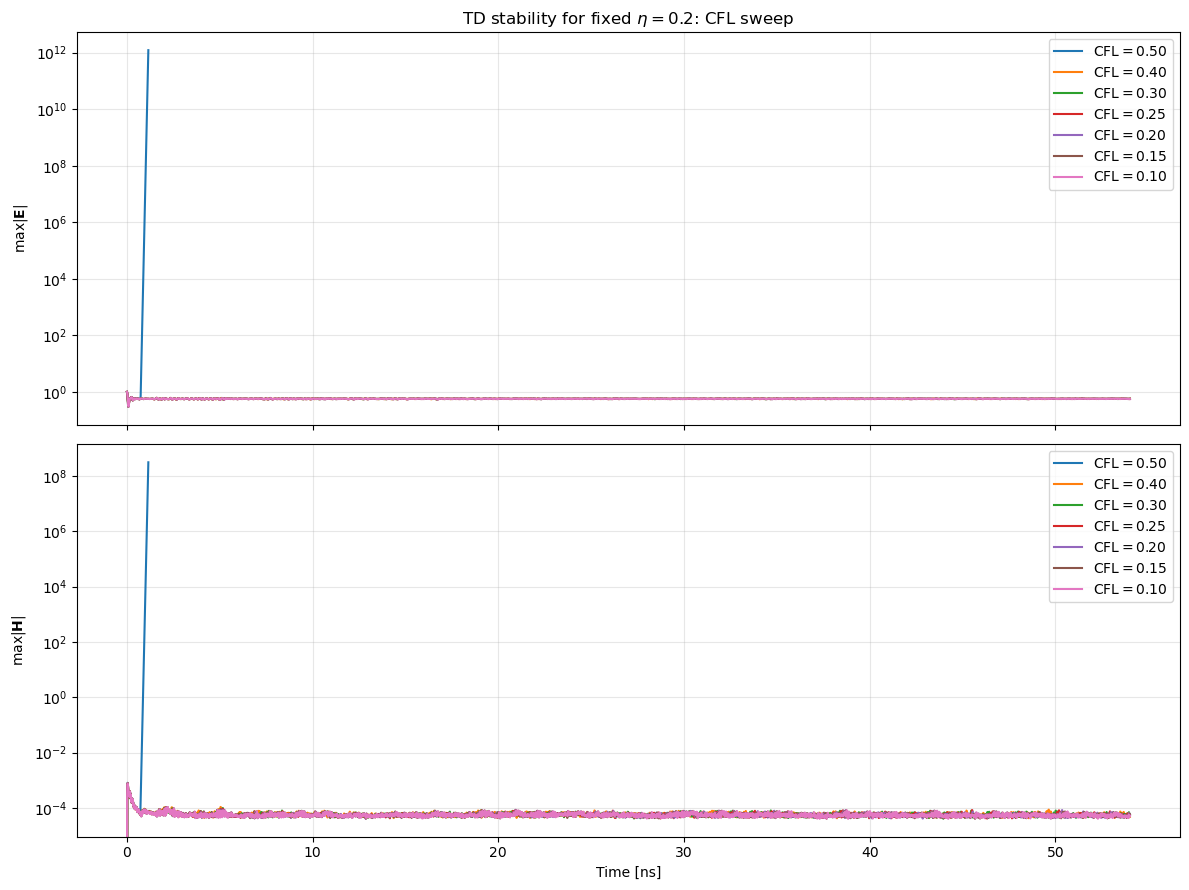


CFL sweep summary
------------------------------------------------------------------------------------------------
cfln=0.50   dt=1.800177e-11 s   steps=   64/ 3000   time=   1.152 ns   stable=False   max|E|=1.225811e+12   max|H|=3.146648e+08
cfln=0.40   dt=1.440141e-11 s   steps= 3750/ 3750   time=  54.005 ns   stable=True   max|E|=1.000000e+00   max|H|=7.734717e-04
cfln=0.30   dt=1.080106e-11 s   steps= 5000/ 5000   time=  54.005 ns   stable=True   max|E|=1.000000e+00   max|H|=7.631025e-04
cfln=0.25   dt=9.000883e-12 s   steps= 6000/ 6000   time=  54.005 ns   stable=True   max|E|=1.000000e+00   max|H|=7.634034e-04
cfln=0.20   dt=7.200706e-12 s   steps= 7500/ 7500   time=  54.005 ns   stable=True   max|E|=1.000000e+00   max|H|=7.590809e-04
cfln=0.15   dt=5.400529e-12 s   steps=10000/10000   time=  54.005 ns   stable=True   max|E|=1.000000e+00   max|H|=7.607740e-04
cfln=0.10   dt=3.600353e-12 s   steps=15000/15000   time=  54.005 ns   stable=True   max|E|=1.000000e+00   max|H|=7.59937

In [10]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
)

for cfln, result in cfl_results.items():
    label = rf"$\mathrm{{CFL}}={cfln:.2f}$"

    axes[0].semilogy(
        result["time"] * 1e9,
        result["max_e"],
        label=label,
    )

    axes[1].semilogy(
        result["time"] * 1e9,
        result["max_h"],
        label=label,
    )

axes[0].set_ylabel(r"$\max |\mathbf{E}|$")

axes[1].set_ylabel(r"$\max |\mathbf{H}|$")

axes[1].set_xlabel("Time [ns]")

axes[0].set_title(
    r"TD stability for fixed "
    r"$\eta=0.2$: CFL sweep"
)

for ax in axes:
    ax.grid(
        True,
        which="both",
        alpha=0.3,
    )
    ax.legend()

plt.tight_layout()
plt.show()

print()
print("CFL sweep summary")
print("-" * 96)

for cfln, result in cfl_results.items():
    final_time = result["time"][-1] * 1e9

    print(
        f"cfln={cfln:4.2f}   "
        f"dt={result['dt']:.6e} s   "
        f"steps={result['completed_steps']:5d}"
        f"/{result['Nt']:5d}   "
        f"time={final_time:8.3f} ns   "
        f"stable={result['stable']}   "
        f"max|E|={np.max(result['max_e']):.6e}   "
        f"max|H|={np.max(result['max_h']):.6e}"
    )

## Legacy simulation

The legacy and conformal cases both use `stl_method="voxelize_rectilinear"`.
This keeps the underlying STL classification method identical and isolates the
effect of the new conformal discretization.


In [13]:
legacy_folder = results_root / "legacy"
legacy_folder.mkdir(parents=True, exist_ok=True)

legacy_ez_file = legacy_folder / "Ez.h5"
if legacy_ez_file.exists():
    legacy_ez_file.unlink()

grid_legacy = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    stl_method="voxelize_rectilinear",
    geometry_mode="legacy",
    subpixel_smoothing=False,
    stl_scale=1.0,
    stl_rotate=[0.0, 0.0, 0.0],
    stl_translate=[0.0, 0.0, 0.0],
    verbose=1,
)

wake_legacy = WakeSolver(
    wakelength=wakelength,
    q=q,
    sigmaz=sigmaz,
    beta=beta,
    xsource=xsource,
    ysource=ysource,
    xtest=xtest,
    ytest=ytest,
    save=False,
    Ez_file=str(legacy_ez_file),
    skip_cells=skip_cells,
    verbose=1,
)

solver_legacy = SolverFIT3D(
    grid_legacy,
    wake_legacy,
    cfln=wake_cfln,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    bg="pec",
    dtype=dtype,
    use_gpu=False,
    verbose=1,
)

solver_legacy.wakesolve(
    wakelength=wakelength,
    save_J=False,
)

Generating grid with 24000 mesh cells...
Importing STL solids...
 * Marking cells inside STL solid 'cavity'...
    * STL solid cavity: 5816 cells marked inside the solid.
 * Marking cells inside STL solid 'shell'...
    * STL solid shell: 2758 cells marked inside the solid.
Total grid initialization time: 0.1613621711730957 s
Initializing Wakefield parameters...
Total solver initialization time: 3.886222839355469e-05 s
Initializing Electromagnetic solver...
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
Calculating maximal stable timestep...
Pre-computing...
Using MKL backend for time-stepping...
Total solver initialization time: 0.02172398567199707 s
Running electromagnetic time-domain simulation...


100%|██████████| 23542/23542 [00:15<00:00, 1497.05it/s]


Reading h5 file _conformal_pillbox_wake/legacy/Ez.h5
Size of the h5 file: 0.06 Gb
Calculating longitudinal wake potential WP(s)


100%|██████████| 210240/210240 [00:38<00:00, 5430.64it/s] 


Elapsed time 38.71402668952942 s
Calculating transverse wake potential WPx, WPy...


100%|██████████| 210240/210240 [00:01<00:00, 171747.88it/s]

Elapsed time 1.2245724201202393 s
Calculating longitudinal impedance Z...
[!] Using analytic charge distribution λ(s) since no data was provided
Calculating transverse impedance Zx, Zy...
Calculation terminated in 40s


## Conformal simulation

Only `geometry_mode` changes. The mesh, STL classification method, material
definitions, source and wake parameters remain identical.


In [ ]:
conformal_folder = results_root / "conformal"
conformal_folder.mkdir(parents=True, exist_ok=True)

conformal_ez_file = conformal_folder / "Ez.h5"
if conformal_ez_file.exists():
    conformal_ez_file.unlink()

grid_conformal = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    stl_method="voxelize_rectilinear",
    geometry_mode="conformal",
    bg_material_type="pec",
    conformal_pec_snap_fraction=conformal_eta,
    subpixel_smoothing=False,
    stl_scale=1.0,
    stl_rotate=[0.0, 0.0, 0.0],
    stl_translate=[0.0, 0.0, 0.0],
    verbose=1,
)

wake_conformal = WakeSolver(
    wakelength=wakelength,
    q=q,
    sigmaz=sigmaz,
    beta=beta,
    xsource=xsource,
    ysource=ysource,
    xtest=xtest,
    ytest=ytest,
    save=False,
    Ez_file=str(conformal_ez_file),
    skip_cells=skip_cells,
    verbose=1,
)

solver_conformal = SolverFIT3D(
    grid_conformal,
    wake_conformal,
    cfln=wake_cfln,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    # bg="vacuum",
    bg="pec",
    dtype=dtype,
    use_gpu=False,
    verbose=1,
)

solver_conformal.wakesolve(
    wakelength=wakelength,
    save_J=False,
)

Generating grid with 24000 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 5816 primal points, 5312 cell centers, and 5781 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 2772 primal points, 1560 cell centers, and 2768 dual points marked inside the solid.
    * primal x-edges: 2630 geometric hits, 2630 crossings, 0 contacts, 573 with multiple crossing positions
    * primal y-edges: 2632 geometric hits, 2632 crossings, 0 contacts, 603 with multiple crossing positions
    * primal z-edges: 1058 geometric hits, 1058 crossings, 0 contacts, 362 with multiple crossing positions
    * dual x-edges: 2484 geometric hits, 2484 crossings, 0 contacts, 558 with multiple crossing positions
    * dual y-edges: 2484 geometric hits, 2484 crossings, 0 contacts, 593 with multiple crossing positions
    * dual z-edges: 1064 geometric hits, 1064 crossings, 0 contacts, 394 with m

  0%|          | 0/18833 [00:00<?, ?it/s]/home/hschreib/Documents/Wakis/WAKIS/wakis/solverFIT3D.py:3404: RuntimeWarning: invalid value encountered in add
  self.E.toarray()
 77%|███████▋  | 14511/18833 [00:12<00:03, 1136.99it/s]


ArgumentError: argument 6: KeyboardInterrupt: 

## Basic numerical checks

Both simulations should produce wake and impedance arrays on compatible axes.
The time steps are also printed so that any difference in the time integration
is immediately visible.


In [73]:
print(f"Legacy dt:    {solver_legacy.dt:.6e} s")
print(f"Conformal dt: {solver_conformal.dt:.6e} s")

print()
print(f"Legacy wake samples:    {len(wake_legacy.WP)}")
print(f"Conformal wake samples: {len(wake_conformal.WP)}")
print(f"Legacy impedance samples:    {len(wake_legacy.Z)}")
print(f"Conformal impedance samples: {len(wake_conformal.Z)}")

Legacy dt:    8.854188e-12 s
Conformal dt: 8.854187e-12 s

Legacy wake samples:    37996
Conformal wake samples: 37996
Legacy impedance samples:    1001
Conformal impedance samples: 1001


In [74]:
wake_conformal.WP[:100]

array([9.15263672e-17, 1.13733113e-16, 1.41107393e-16, 1.74810104e-16,
       2.16257912e-16, 2.67179521e-16, 3.29683933e-16, 4.06343345e-16,
       5.00292827e-16, 6.15351796e-16, 7.56168592e-16, 9.28395814e-16,
       1.13890080e-15, 1.39601685e-15, 1.70984610e-15, 2.09261994e-15,
       2.55913773e-15, 3.12728484e-15, 3.81865832e-15, 4.65931470e-15,
       5.68066431e-15, 6.92054464e-15, 8.42449547e-15, 1.02472943e-14,
       1.24547593e-14, 1.51259218e-14, 1.83556012e-14, 2.22574665e-14,
       2.69676622e-14, 3.26490712e-14, 3.94964586e-14, 4.77424273e-14,
       5.76646000e-14, 6.95939600e-14, 8.39248111e-14, 1.01126338e-13,
       1.21756410e-13, 1.46477984e-13, 1.76077575e-13, 2.11488060e-13,
       2.53814289e-13, 3.04364149e-13, 3.64684449e-13, 4.36601693e-13,
       5.22272759e-13, 6.24239259e-13, 7.45495943e-13, 8.89567483e-13,
       1.06059668e-12, 1.26345062e-12, 1.50383618e-12, 1.78844669e-12,
       2.12511802e-12, 2.52301415e-12, 2.99284651e-12, 3.54711244e-12,
      

## Wake-potential comparison


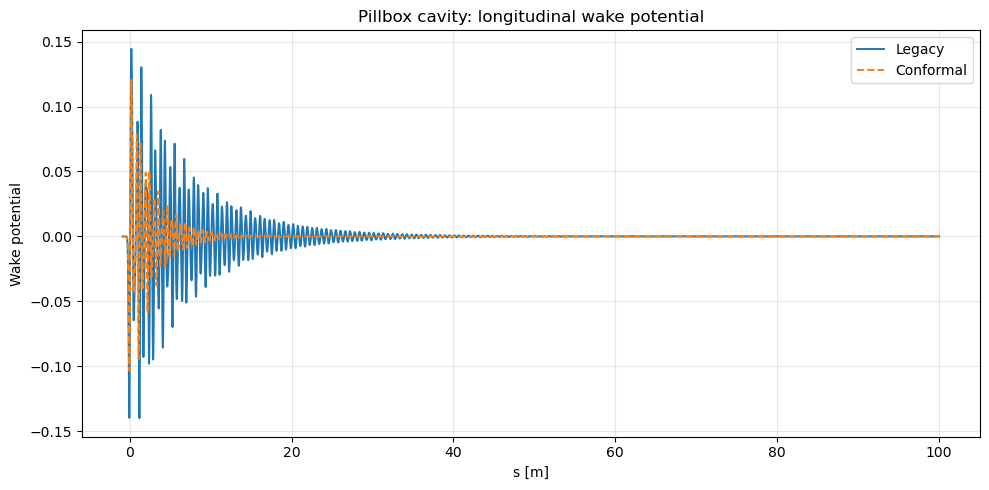

In [75]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    wake_legacy.s,
    wake_legacy.WP,
    linewidth=1.4,
    label="Legacy",
)

ax.plot(
    wake_conformal.s,
    wake_conformal.WP,
    linewidth=1.4,
    linestyle="--",
    label="Conformal",
)

ax.set_xlabel("s [m]")
ax.set_ylabel("Wake potential")
ax.set_title("Pillbox cavity: longitudinal wake potential")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

## Longitudinal impedance comparison

The magnitude is the most convenient first comparison because shifts in the
cavity resonances become immediately visible.


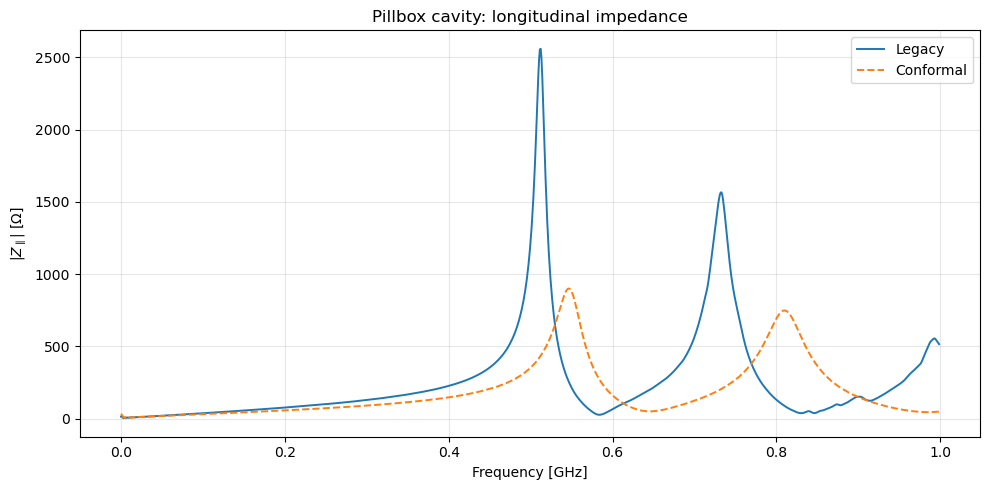

In [76]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    wake_legacy.f / 1e9,
    np.abs(wake_legacy.Z),
    linewidth=1.4,
    label="Legacy",
)

ax.plot(
    wake_conformal.f / 1e9,
    np.abs(wake_conformal.Z),
    linewidth=1.4,
    linestyle="--",
    label="Conformal",
)

ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel(r"$|Z_\parallel|$ [$\Omega$]")
ax.set_title("Pillbox cavity: longitudinal impedance")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

## Real and imaginary parts

This plot helps distinguish an actual resonance-frequency shift from a change
only in peak magnitude.


In [ ]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(10, 8),
    sharex=True,
)

axes[0].plot(
    wake_legacy.f / 1e9,
    np.real(wake_legacy.Z),
    linewidth=1.3,
    label="Legacy",
)

axes[0].plot(
    wake_conformal.f / 1e9,
    np.real(wake_conformal.Z),
    linewidth=1.3,
    linestyle="--",
    label="Conformal",
)

axes[0].set_ylabel(r"Re$(Z_\parallel)$ [$\Omega$]")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    wake_legacy.f / 1e9,
    np.imag(wake_legacy.Z),
    linewidth=1.3,
    label="Legacy",
)

axes[1].plot(
    wake_conformal.f / 1e9,
    np.imag(wake_conformal.Z),
    linewidth=1.3,
    linestyle="--",
    label="Conformal",
)

axes[1].set_xlabel("Frequency [GHz]")
axes[1].set_ylabel(r"Im$(Z_\parallel)$ [$\Omega$]")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.suptitle("Pillbox cavity: longitudinal impedance")
fig.tight_layout()
plt.show()

## Relative differences

These diagnostics are normalized by the maximum magnitude of the legacy
solution rather than pointwise, so zeros in the wake or impedance do not
artificially produce huge relative errors.


In [ ]:
if np.array_equal(wake_legacy.s, wake_conformal.s):
    wake_difference = wake_conformal.WP - wake_legacy.WP
    wake_relative_difference = wake_difference / max(
        np.max(np.abs(wake_legacy.WP)), 1e-30
    )

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(
        wake_legacy.s,
        wake_relative_difference,
    )

    ax.set_xlabel("s [m]")
    ax.set_ylabel(
        r"$(W_\mathrm{conf}-W_\mathrm{legacy})/"
        r"\max|W_\mathrm{legacy}|$"
    )
    ax.set_title("Normalized wake-potential difference")
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()
else:
    print("Wake axes differ; direct pointwise wake subtraction was skipped.")

In [ ]:
if np.array_equal(wake_legacy.f, wake_conformal.f):
    impedance_difference = np.abs(wake_conformal.Z) - np.abs(wake_legacy.Z)

    impedance_relative_difference = impedance_difference / max(
        np.max(np.abs(wake_legacy.Z)), 1e-30
    )

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(
        wake_legacy.f / 1e9,
        impedance_relative_difference,
    )

    ax.set_xlabel("Frequency [GHz]")
    ax.set_ylabel(
        r"$(|Z|_\mathrm{conf}-|Z|_\mathrm{legacy})/"
        r"\max|Z_\mathrm{legacy}|$"
    )
    ax.set_title("Normalized impedance-magnitude difference")
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()
else:
    print("Frequency axes differ; direct pointwise impedance subtraction was skipped.")